In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.io as sio

MAT_PATH = "../../data/raw/lfp_data.mat"

def describe(name, v, indent=""):
    """Print what a variable is: its type, shape, and (for structs) field names."""
    if hasattr(v, "_fieldnames"):                       # a MATLAB struct
        print(f"{indent}{name}: struct with fields {v._fieldnames}")
    elif isinstance(v, np.ndarray) and v.dtype == object and v.size > 0:
        print(f"{indent}{name}: array of {v.size} items, shape {v.shape}")
        describe(f"{name}[0]", v.flat[0], indent + "    ")   # peek at the first item
    else:
        print(f"{indent}{name}: {type(v).__name__}, shape {getattr(v, 'shape', None)}, "
              f"dtype {getattr(v, 'dtype', None)}")

try:
    mat = sio.loadmat(MAT_PATH, squeeze_me=True, struct_as_record=False)
    print("Format: older MATLAB (.mat v7 or earlier), loaded with scipy\n")
    for k, v in mat.items():
        if not k.startswith("__"):                      # skip MATLAB's header entries
            describe(k, v)
except NotImplementedError:
    import h5py
    print("Format: MATLAB v7.3 (HDF5), opening with h5py\n")
    f = h5py.File(MAT_PATH, "r")
    f.visititems(lambda name, obj: print(name, getattr(obj, "shape", ""), getattr(obj, "dtype", "")))

Format: older MATLAB (.mat v7 or earlier), loaded with scipy

LFP: array of 18 items, shape (6, 3)
    LFP[0]: ndarray, shape (2442112,), dtype float32


Sharpest peaks (rat 1, session 1):
  0.05898 cycles/sample (×2961 above neighbors) -> fs ≈ 1017 Hz if it's 60 Hz noise, 848 Hz if it's 50 Hz
  0.11792 cycles/sample (×123 above neighbors) -> fs ≈ 509 Hz if it's 60 Hz noise, 424 Hz if it's 50 Hz
  0.17686 cycles/sample (×117 above neighbors) -> fs ≈ 339 Hz if it's 60 Hz noise, 283 Hz if it's 50 Hz
  0.17690 cycles/sample (×174 above neighbors) -> fs ≈ 339 Hz if it's 60 Hz noise, 283 Hz if it's 50 Hz
  0.29483 cycles/sample (×219 above neighbors) -> fs ≈ 204 Hz if it's 60 Hz noise, 170 Hz if it's 50 Hz


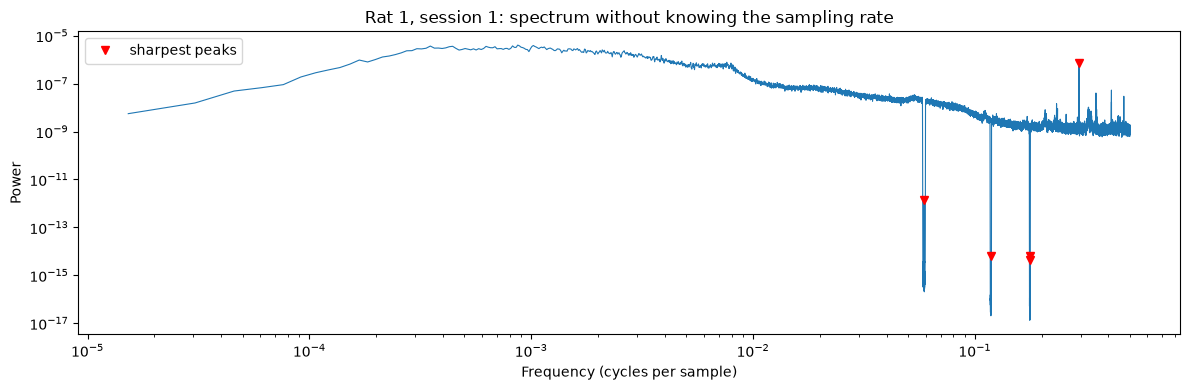

In [4]:
from scipy import signal
from scipy.ndimage import median_filter

x = LFP[0, 0].astype(np.float64)
f, p = signal.welch(x, fs=1.0, nperseg=2**16)     # frequency in cycles per sample

# Find sharp, narrow peaks (much taller than their neighbors), like line noise
ratio = p / median_filter(p, size=51)
cand = signal.find_peaks(ratio, height=5)[0]
top = cand[np.argsort(ratio[cand])[::-1][:5]]      # 5 sharpest peaks

print("Sharpest peaks (rat 1, session 1):")
for i in sorted(top):
    print(f"  {f[i]:.5f} cycles/sample (×{ratio[i]:.0f} above neighbors) -> "
          f"fs ≈ {60 / f[i]:.0f} Hz if it's 60 Hz noise, {50 / f[i]:.0f} Hz if it's 50 Hz")

fig, ax = plt.subplots(figsize=(12, 4))
ax.loglog(f[1:], p[1:], lw=0.8)
ax.plot(f[top], p[top], "rv", label="sharpest peaks")
ax.set_xlabel("Frequency (cycles per sample)")
ax.set_ylabel("Power")
ax.set_title("Rat 1, session 1: spectrum without knowing the sampling rate")
ax.legend()
plt.tight_layout()
plt.show()

**On hold:** We still need Jonathan to tell us what the 3 sessions are (which states), which brain region the channel is from, and to confirm the sampling rate (our estimate is ~1017 Hz). We can't make the state comparison until he answers.